# Ising deduplication

Fit a maximum entropy (Ising) model to a co-viewing matrix, check how good the fit is, see how much the overlap changes reach, and split a budget across channels. The write-up is in [`notes/findings.md`](../notes/findings.md).

In [1]:
import time
from pathlib import Path

import jax.numpy as jnp
import matplotlib.pyplot as plt
from jax import random

from ising_deduplication import (
    exact_moments,
    exact_probs,
    fit_with_adam,
    fit_with_sgd,
    gen_xs,
    get_conversions_exact,
    independent_init,
    optimize_with_adam,
    run_ising_chain,
)
from ising_deduplication.fitting import (
    compute_exact_gradient,
    compute_surrogate_gradient,
)

IMG = Path("../notes/img")
IMG.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": "#e4e3df",
        "grid.linewidth": 0.8,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "text.color": INK,
        "lines.linewidth": 2,
        "legend.frameon": False,
        "font.size": 10,
    }
)

## The co-viewing matrix

`target[i, j]` is the share of people who watch both channel `i` and channel `j`, and the diagonal is the share who watch each channel. Channels 0 and 1 overlap a lot (78% watch both, vs 72% if they were independent), and channel 2 overlaps less with channel 1 than independence would give (20% vs 24%).

In [2]:
target = jnp.array([[0.9, 0.78, 0.27], [0.78, 0.8, 0.2], [0.27, 0.2, 0.3]])
p = target.diagonal()
print("if independent:\n", jnp.round(jnp.outer(p, p).at[jnp.diag_indices(3)].set(p), 3))

if independent:
 [[0.90000004 0.72       0.27      ]
 [0.72       0.8        0.24000001]
 [0.27       0.24000001 0.3       ]]


## Fitting

Both methods, with Adam at the default settings. The exact method enumerates all $2^3 = 8$ viewers, the surrogate uses a fresh 10,000 step MCMC chain for every step.

In [3]:
fits = {}
for method in ["exact", "surrogate"]:
    t = time.time()
    M, (Ms, losses) = fit_with_adam(target, method=method)
    M.block_until_ready()
    fits[method] = (M, Ms, losses)
    print(f"{method}: {time.time() - t:.1f}s")

M_exact, Ms_exact, _ = fits["exact"]
M_sur, Ms_sur, _ = fits["surrogate"]
M_sur_avg = Ms_sur[-200:].mean(axis=0)

print("fitted M (exact):\n", jnp.round(M_exact, 3))
for name, M in [
    ("exact", M_exact),
    ("surrogate, final", M_sur),
    ("surrogate, avg of last 200", M_sur_avg),
]:
    err = jnp.abs(exact_moments(M) - target).max()
    print(f"{name:28s} worst |model - target| = {float(err):.4f}")

exact: 0.4s


surrogate: 66.9s
fitted M (exact):
 [[-0.024       1.7370001   0.47300002]
 [ 1.7370001  -0.998      -0.73300004]
 [ 0.47300002 -0.73300004 -0.56      ]]


exact                        worst |model - target| = 0.0006
surrogate, final             worst |model - target| = 0.0119
surrogate, avg of last 200   worst |model - target| = 0.0041


The surrogate's final iterate is a couple of percentage points off, because the gradient is noisy and Adam keeps bouncing around. Averaging the last 200 iterates removes most of that. A single fresh MCMC chain isn't a good check of the fit, since it has about 1pp of noise itself:

In [4]:
xs = run_ising_chain(M_sur, n_steps=10_000, rng_key=random.PRNGKey(123))[0]
print(
    f"P(watch 0 and 1): chain {float((xs[:, 0] * xs[:, 1]).mean()):.1%}, "
    f"exact {float(exact_moments(M_sur)[0, 1]):.1%}, target {float(target[0, 1]):.1%}"
)


def chain_moments(M, key):
    x = run_ising_chain(M, n_steps=10_000, rng_key=key)[0]
    return (x[:, :, None] * x[:, None, :]).mean(axis=0)


ests = jnp.stack([chain_moments(M_sur, random.PRNGKey(k)) for k in range(20)])
print("std of a 10k step chain's estimate:\n", jnp.round(ests.std(0), 4))

P(watch 0 and 1): chain 77.7%, exact 76.8%, target 78.0%


std of a 10k step chain's estimate:
 [[0.0069 0.0098 0.0079]
 [0.0098 0.0093 0.0053]
 [0.0079 0.0053 0.0097]]


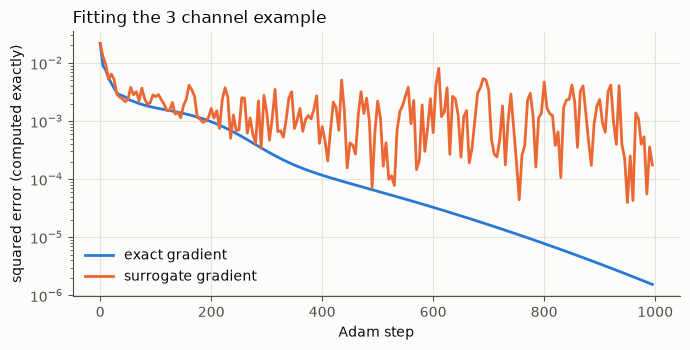

In [5]:
def exact_loss_path(Ms):
    return jnp.array([((exact_moments(M) - target) ** 2).sum() for M in Ms[::5]])


steps = jnp.arange(0, Ms_exact.shape[0], 5)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(steps, exact_loss_path(Ms_exact), color=BLUE, label="exact gradient")
ax.plot(steps, exact_loss_path(Ms_sur), color=ORANGE, label="surrogate gradient")
ax.set_yscale("log")
ax.set_xlabel("Adam step")
ax.set_ylabel("squared error (computed exactly)")
ax.set_title("Fitting the 3 channel example", loc="left")
ax.legend()
fig.tight_layout()
fig.savefig(IMG / "fit.png", dpi=150)

### Plain gradient descent

Much slower on this loss, with either gradient.

In [6]:
for method in ["exact", "surrogate"]:
    M, _ = fit_with_sgd(target, method=method)
    print(
        f"sgd {method:9s} worst |model - target| = {float(jnp.abs(exact_moments(M) - target).max()):.4f}"
    )

sgd exact     worst |model - target| = 0.0315


sgd surrogate worst |model - target| = 0.0282


### How good is the surrogate gradient?

Compare it with the exact gradient at the starting point and at a random point.

In [7]:
def cosine(a, b):
    return float((a * b).sum() / jnp.linalg.norm(a) / jnp.linalg.norm(b))


xs_all = gen_xs(3)
M0 = independent_init(target)
for name, M in [
    ("independent start", M0),
    ("random point", M0 + 0.5 * random.normal(random.PRNGKey(3), (3, 3))),
]:
    _, g_exact = compute_exact_gradient(M, target, xs_all)
    gs = jnp.stack(
        [
            compute_surrogate_gradient(M, target, random.PRNGKey(k), 10_000)[1]
            for k in range(20)
        ]
    )
    single = [cosine(g, g_exact) for g in gs]
    print(
        f"{name}: cos(single chain) {min(single):.2f}-{max(single):.2f}, "
        f"cos(mean of 20) {cosine(gs.mean(0), g_exact):.3f}, "
        f"size ratio {float(jnp.linalg.norm(gs.mean(0)) / jnp.linalg.norm(g_exact)):.2f}"
    )

independent start: cos(single chain) 0.79-1.00, cos(mean of 20) 0.973, size ratio 0.49


random point: cos(single chain) 0.99-1.00, cos(mean of 20) 0.997, size ratio 0.38


## Deduplication

How much does the overlap change things, compared with assuming people watch channels independently?

In [8]:
M_ind = independent_init(target)
ps = exact_probs(M_exact, xs_all)
print(
    f"watch none of the channels: fitted {float(ps[0]):.1%}, independent {float(exact_probs(M_ind, xs_all)[0]):.1%}"
)

q = jnp.ones(3) * 0.9
N = 2_000_000
for plan in [[1e6, 1e6, 0], [1e6, 0, 1e6], [1e6, 1e6, 1e6]]:
    plan = jnp.array(plan)
    r_fit = get_conversions_exact(plan, M_exact, xs_all, q, N) / N
    r_ind = get_conversions_exact(plan, M_ind, xs_all, q, N) / N
    print(
        f"impressions {[int(i) for i in plan]}: fitted {float(r_fit):.1%}, independent {float(r_ind):.1%}"
    )

watch none of the channels: fitted 5.0%, independent 1.4%


impressions [1000000, 1000000, 0]: fitted 56.7%, independent 57.6%
impressions [1000000, 0, 1000000]: fitted 50.5%, independent 50.5%
impressions [1000000, 1000000, 1000000]: fitted 67.7%, independent 67.5%


## Optimising the split

For a few budgets, find the best split under the fitted model and under the independent model, and score every split with the fitted model.

In [9]:
results = {}
for T in [100_000, 1_000_000, 2_000_000, 5_000_000]:
    plans = {
        "fitted (exact)": optimize_with_adam(M_exact, T, q, N, method="exact")[0],
        "fitted (surrogate)": optimize_with_adam(M_exact, T, q, N, method="surrogate")[
            0
        ],
        "independent": optimize_with_adam(M_ind, T, q, N, method="exact")[0],
        "even": jnp.ones(3) * T / 3,
        "proportional to audience": p / p.sum() * T,
    }
    results[T] = plans
    print(f"budget {T:,}")
    for name, plan in plans.items():
        r = get_conversions_exact(plan, M_exact, xs_all, q, N)
        share = plan / T
        print(
            f"  {name:26s} split {share[0]:.0%} / {share[1]:.0%} / {share[2]:.0%}   converted {float(r):>11,.0f} ({float(r) / N:.2%})"
        )

budget 100,000
  fitted (exact)             split 75% / 19% / 6%   converted      87,812 (4.39%)
  fitted (surrogate)         split 78% / 17% / 5%   converted      87,812 (4.39%)
  independent                split 67% / 30% / 3%   converted      87,803 (4.39%)
  even                       split 33% / 33% / 33%   converted      87,469 (4.37%)
  proportional to audience   split 45% / 40% / 15%   converted      87,765 (4.39%)


budget 1,000,000
  fitted (exact)             split 72% / 21% / 7%   converted     710,530 (35.53%)
  fitted (surrogate)         split 75% / 19% / 6%   converted     710,482 (35.52%)
  independent                split 65% / 31% / 4%   converted     709,809 (35.49%)
  even                       split 33% / 33% / 33%   converted     689,934 (34.50%)
  proportional to audience   split 45% / 40% / 15%   converted     707,952 (35.40%)


budget 2,000,000
  fitted (exact)             split 69% / 23% / 8%   converted   1,146,070 (57.30%)
  fitted (surrogate)         split 72% / 22% / 7%   converted   1,145,925 (57.30%)
  independent                split 63% / 33% / 4%   converted   1,143,840 (57.19%)
  even                       split 33% / 33% / 33%   converted   1,098,878 (54.94%)
  proportional to audience   split 45% / 40% / 15%   converted   1,140,839 (57.04%)


budget 5,000,000
  fitted (exact)             split 60% / 29% / 11%   converted   1,689,397 (84.47%)
  fitted (surrogate)         split 62% / 28% / 10%   converted   1,689,095 (84.45%)
  independent                split 59% / 35% / 5%   converted   1,682,224 (84.11%)
  even                       split 33% / 33% / 33%   converted   1,629,027 (81.45%)
  proportional to audience   split 45% / 40% / 15%   converted   1,685,394 (84.27%)


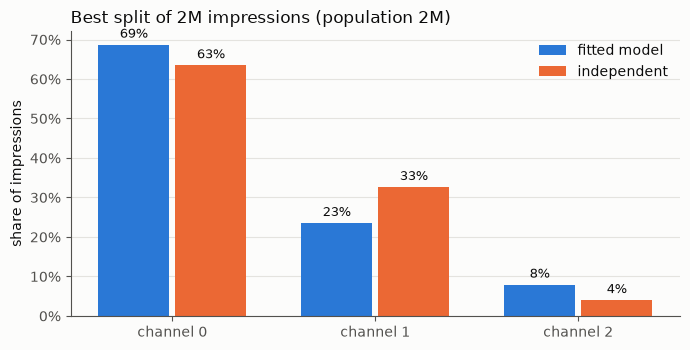

In [10]:
T = 2_000_000
fig, ax = plt.subplots(figsize=(7, 3.6))
width = 0.38
x = jnp.arange(3)
for offset, name, color in [
    (-width / 2, "fitted (exact)", BLUE),
    (width / 2, "independent", ORANGE),
]:
    share = results[T][name] / T
    bars = ax.bar(
        x + offset,
        share,
        width - 0.03,
        color=color,
        label=name.replace(" (exact)", " model"),
    )
    ax.bar_label(
        bars, labels=[f"{s:.0%}" for s in share], padding=3, color=INK, fontsize=9
    )
ax.set_xticks(x, ["channel 0", "channel 1", "channel 2"])
ax.set_ylabel("share of impressions")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Best split of 2M impressions (population 2M)", loc="left")
ax.grid(axis="x", visible=False)
ax.legend()
fig.tight_layout()
fig.savefig(IMG / "split.png", dpi=150)

## More channels

A random ground-truth model with `n` channels, fit with both methods. The surrogate's cost depends on the chain length, not the number of channels, while the exact method's doubles with every channel.

In [11]:
for n in [6, 10, 14]:
    k1, k2 = random.split(random.PRNGKey(n))
    A = 0.5 * random.normal(k1, (n, n))
    A = (A + A.T) / 2
    A = A.at[jnp.diag_indices(n)].set(random.normal(k2, (n,)) - 1)
    tgt = exact_moments(A)
    for method in ["exact", "surrogate"]:
        t = time.time()
        M, (Ms, _) = fit_with_adam(tgt, method=method)
        M.block_until_ready()
        dt = time.time() - t
        err = float(jnp.abs(exact_moments(M) - tgt).max())
        err_avg = float(jnp.abs(exact_moments(Ms[-200:].mean(0)) - tgt).max())
        print(
            f"n={n:2d} {method:9s} {dt:5.1f}s  worst error: final {err:.3f}, avg of last 200 {err_avg:.3f}"
        )

n= 6 exact       0.4s  worst error: final 0.001, avg of last 200 0.000


n= 6 surrogate  85.9s  worst error: final 0.017, avg of last 200 0.005


n=10 exact       0.5s  worst error: final 0.002, avg of last 200 0.001


n=10 surrogate  79.1s  worst error: final 0.029, avg of last 200 0.008


n=14 exact       2.4s  worst error: final 0.032, avg of last 200 0.033


n=14 surrogate  73.0s  worst error: final 0.059, avg of last 200 0.019
